# Day 8 – RetailMind AI: Computer Vision

This notebook performs:
1. Load real fashion product images and metadata.
2. Display and inspect product images.
3. Segment the foreground product and remove the background with `rembg`.
4. Save transparent and white-background images.
5. Load the Day 6 product CNN.
6. Generate a Grad-CAM heatmap to visualize image regions influencing the CNN prediction.

**Dataset location:** `RETAILMIND_AI/myntradataset/`  
**Expected files:** `myntradataset/styles.csv` and `myntradataset/images/<id>.jpg`

Run cells from top to bottom. The Day 6 product CNN must already exist in `models/day6_product_cnn.keras`.

## 1. Install dependencies

In [2]:
%pip install -q pandas numpy matplotlib pillow tensorflow rembg onnxruntime

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Imports and project paths

In [3]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from PIL import Image
from rembg import remove
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "myntradataset"
IMAGE_DIR = DATA_DIR / "images"
CSV_PATH = DATA_DIR / "styles.csv"

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_PATH = MODEL_DIR / "day6_product_cnn.keras"
CLASS_NAMES_PATH = MODEL_DIR / "day6_class_names.json"

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "day8"
SEGMENTED_DIR = OUTPUT_DIR / "segmented"
WHITE_BG_DIR = OUTPUT_DIR / "white_background"
HEATMAP_DIR = OUTPUT_DIR / "gradcam"

for folder in [SEGMENTED_DIR, WHITE_BG_DIR, HEATMAP_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Dataset exists:", CSV_PATH.exists())
print("Images folder exists:", IMAGE_DIR.exists())
print("Day 6 model exists:", MODEL_PATH.exists())
print("Class names exist:", CLASS_NAMES_PATH.exists())

Project root: c:\Users\ANSHU SHAW\OneDrive\Desktop\RETAILMIND_AI
Dataset exists: True
Images folder exists: True
Day 6 model exists: True
Class names exist: True


## 3. Load product metadata

In [4]:
if not CSV_PATH.exists():
    raise FileNotFoundError(f"styles.csv not found: {CSV_PATH}")

df = pd.read_csv(CSV_PATH, on_bad_lines="skip")
df.columns = df.columns.str.strip()

df = df.dropna(subset=["id", "masterCategory"]).copy()
df["id"] = pd.to_numeric(df["id"], errors="coerce")
df = df.dropna(subset=["id"]).copy()
df["id"] = df["id"].astype("int64")

df["image_path"] = df["id"].map(lambda x: IMAGE_DIR / f"{x}.jpg")
df = df[df["image_path"].map(lambda p: p.exists())].copy()
df = df.drop_duplicates(subset=["id"]).reset_index(drop=True)

print("Dataset shape:", df.shape)
print("Available columns:", df.columns.tolist())
display(df.head())
print(df["masterCategory"].value_counts().head(15))

Dataset shape: (44419, 11)
Available columns: ['id', 'gender', 'masterCategory', 'subCategory', 'articleType', 'baseColour', 'season', 'year', 'usage', 'productDisplayName', 'image_path']


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName,image_path
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt,c:\Users\ANSHU SHAW\OneDrive\Desktop\RETAILMIN...
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans,c:\Users\ANSHU SHAW\OneDrive\Desktop\RETAILMIN...
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch,c:\Users\ANSHU SHAW\OneDrive\Desktop\RETAILMIN...
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants,c:\Users\ANSHU SHAW\OneDrive\Desktop\RETAILMIN...
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt,c:\Users\ANSHU SHAW\OneDrive\Desktop\RETAILMIN...


masterCategory
Apparel           21392
Accessories       11274
Footwear           9219
Personal Care      2403
Free Items          105
Sporting Goods       25
Home                  1
Name: count, dtype: int64


## 4. Display sample product images

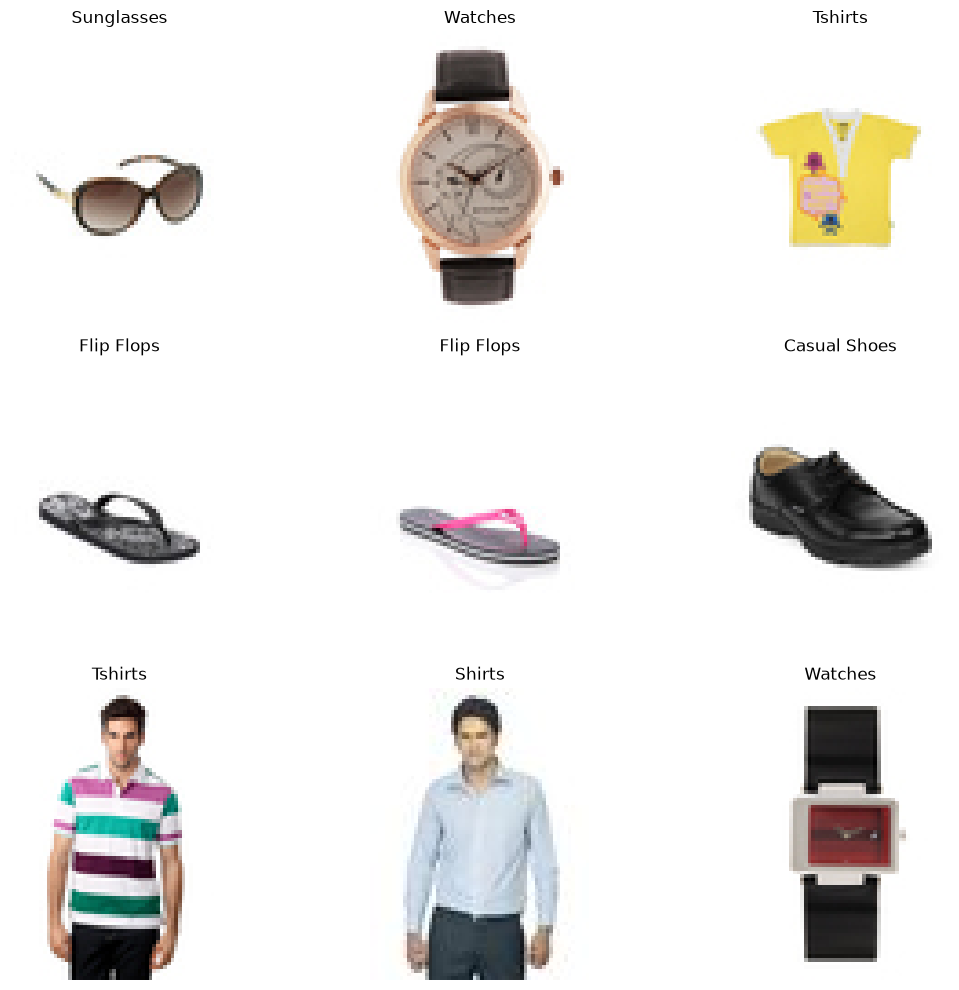

In [5]:
sample_df = df.sample(min(9, len(df)), random_state=42)

plt.figure(figsize=(12, 10))
for i, (_, row) in enumerate(sample_df.iterrows(), start=1):
    image = Image.open(row["image_path"]).convert("RGB")
    plt.subplot(3, 3, i)
    plt.imshow(image)
    plt.title(str(row["articleType"]) if pd.notna(row.get("articleType")) else str(row["masterCategory"]))
    plt.axis("off")

plt.tight_layout()
plt.show()

## 5. Foreground segmentation and background removal

`rembg` uses a pretrained foreground/background segmentation model. It returns an image with an alpha channel:
- Product pixels remain visible.
- Background pixels become transparent.

This is foreground segmentation/background removal; it does not create separate semantic masks for clothing parts.

In [ ]:
from rembg import remove, new_session

rembg_session = new_session("u2netp")


def remove_product_background(image_path, save_path):
    input_image = Image.open(image_path).convert("RGBA")

    output_image = remove(
        input_image,
        session=rembg_session
    )

    output_image.save(save_path)

    return output_image


sample_row = df.iloc[0]

sample_id = int(sample_row["id"])
sample_input_path = Path(sample_row["image_path"])
sample_segmented_path = SEGMENTED_DIR / f"{sample_id}_transparent.png"

segmented_image = remove_product_background(
    sample_input_path,
    sample_segmented_path
)

print("Original image:", sample_input_path)
print("Segmented image:", sample_segmented_path)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(Image.open(sample_input_path).convert("RGB"))
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(segmented_image)
plt.title("Foreground Segmentation")
plt.axis("off")

plt.tight_layout()
plt.show()

Fail: [ONNXRuntimeError] : 1 : FAIL : Non-zero status code returned while running Sum node. Name:'/model/decoder/decoder_block1/dec_att/aspp_deforms.2/atrous_conv/Sum' Status Message: N:\_work\1\s\onnxruntime\core\framework\bfc_arena.cc:360 onnxruntime::BFCArena::AllocateRawInternal Failed to allocate memory for requested buffer of size 822083584


## 6. Create a white-background product image

In [ ]:
def create_white_background_image(segmented_image, save_path):
    foreground = segmented_image.convert("RGBA")
    white_background = Image.new("RGBA", foreground.size, (255, 255, 255, 255))
    white_background.alpha_composite(foreground)
    result = white_background.convert("RGB")
    result.save(save_path, quality=95)
    return result

white_bg_path = WHITE_BG_DIR / f"{sample_id}_white.jpg"
white_image = create_white_background_image(segmented_image, white_bg_path)

print("Saved:", white_bg_path)

plt.figure(figsize=(6, 6))
plt.imshow(white_image)
plt.title("Product on white background")
plt.axis("off")
plt.show()

## 7. Process multiple product images

In [ ]:
MAX_IMAGES = 20
processed_count = 0

for _, row in df.head(MAX_IMAGES).iterrows():
    product_id = int(row["id"])
    input_path = Path(row["image_path"])

    transparent_path = SEGMENTED_DIR / f"{product_id}_transparent.png"
    white_path = WHITE_BG_DIR / f"{product_id}_white.jpg"

    try:
        if not transparent_path.exists():
            segmented = remove_product_background(input_path, transparent_path)
        else:
            segmented = Image.open(transparent_path).convert("RGBA")

        if not white_path.exists():
            create_white_background_image(segmented, white_path)

        processed_count += 1

    except Exception as error:
        print(f"Skipped {product_id}: {error}")

print("Successfully processed:", processed_count)
print("Transparent images:", len(list(SEGMENTED_DIR.glob("*.png"))))
print("White-background images:", len(list(WHITE_BG_DIR.glob("*.jpg"))))

## 8. Load the Day 6 product CNN

The uploaded Day 6 notebook saves the real product model as `models/day6_product_cnn.keras` and its class mapping as `models/day6_class_names.json`.

The Fashion-MNIST model is a different model and must not be used here.

In [ ]:
if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Day 6 product CNN not found: {MODEL_PATH}. "
        "Run the real Fashion Product Images training and save cells from Day 6 first."
    )

if not CLASS_NAMES_PATH.exists():
    raise FileNotFoundError(
        f"Class names file not found: {CLASS_NAMES_PATH}. "
        "Run the Day 6 class-name saving cell first."
    )

model = tf.keras.models.load_model(MODEL_PATH)

with open(CLASS_NAMES_PATH, "r", encoding="utf-8") as file:
    class_names = json.load(file)

IMG_SIZE = 128

print("Model loaded.")
print("Classes:", class_names)
model.summary()

## 9. Predict a product category

In [ ]:
def prepare_image(image_path):
    image = tf.keras.utils.load_img(
        image_path,
        target_size=(IMG_SIZE, IMG_SIZE),
        color_mode="rgb"
    )
    array = tf.keras.utils.img_to_array(image).astype("float32") / 255.0
    return np.expand_dims(array, axis=0)

def predict_product(image_path):
    image_array = prepare_image(image_path)
    probabilities = model.predict(image_array, verbose=0)[0]
    predicted_index = int(np.argmax(probabilities))

    return {
        "category": class_names[predicted_index],
        "confidence": float(probabilities[predicted_index]) * 100,
        "probabilities": probabilities
    }

prediction = predict_product(sample_input_path)

print("Predicted category:", prediction["category"])
print(f"Confidence: {prediction['confidence']:.2f}%")

## 10. Grad-CAM heatmap

Grad-CAM uses gradients flowing into the final convolution layer to highlight image regions that influenced the CNN prediction. The layer is detected automatically from the loaded Day 6 model.

In [ ]:
conv_layers = [
    layer for layer in model.layers
    if isinstance(layer, tf.keras.layers.Conv2D)
]

if not conv_layers:
    raise ValueError("No Conv2D layer found in the loaded model.")

last_conv_layer = conv_layers[-1]
print("Grad-CAM layer:", last_conv_layer.name)

grad_model = tf.keras.models.Model(
    inputs=model.inputs,
    outputs=[last_conv_layer.output, model.output]
)

def make_gradcam_heatmap(image_array, grad_model, class_index=None):
    image_tensor = tf.convert_to_tensor(image_array)

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(image_tensor, training=False)
        if class_index is None:
            class_index = tf.argmax(predictions[0])
        class_score = predictions[:, class_index]

    gradients = tape.gradient(class_score, conv_outputs)
    pooled_gradients = tf.reduce_mean(gradients, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = tf.reduce_sum(conv_outputs * pooled_gradients, axis=-1)

    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + tf.keras.backend.epsilon())

    return heatmap.numpy()

image_array = prepare_image(sample_input_path)
heatmap = make_gradcam_heatmap(image_array, grad_model)

## 11. Overlay Grad-CAM on the original image

In [ ]:
def display_gradcam(image_path, heatmap, save_path=None):
    original = Image.open(image_path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    original_array = np.array(original)

    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis],
        (IMG_SIZE, IMG_SIZE)
    ).numpy().squeeze()

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(original_array)
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(heatmap_resized, cmap="jet")
    plt.title("Grad-CAM heatmap")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(original_array)
    plt.imshow(heatmap_resized, cmap="jet", alpha=0.4)
    plt.title("Grad-CAM overlay")
    plt.axis("off")

    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, bbox_inches="tight")

    plt.show()

gradcam_path = HEATMAP_DIR / f"{sample_id}_gradcam.png"
display_gradcam(sample_input_path, heatmap, gradcam_path)

print("Grad-CAM saved:", gradcam_path)

## 12. Run prediction and Grad-CAM for another product

In [ ]:
test_row = df.iloc[min(10, len(df) - 1)]
test_image_path = Path(test_row["image_path"])
test_id = int(test_row["id"])

test_prediction = predict_product(test_image_path)

print("Product ID:", test_id)
print("Actual category:", test_row["masterCategory"])
print("Predicted category:", test_prediction["category"])
print(f"Confidence: {test_prediction['confidence']:.2f}%")

test_array = prepare_image(test_image_path)
test_heatmap = make_gradcam_heatmap(test_array)

display_gradcam(
    test_image_path,
    test_heatmap,
    HEATMAP_DIR / f"{test_id}_gradcam.png"
)

## 13. Save a Day 8 processing summary

In [ ]:
summary = {
    "dataset_rows_with_images": int(len(df)),
    "images_processed_for_background_removal": int(len(list(SEGMENTED_DIR.glob("*.png")))),
    "white_background_images": int(len(list(WHITE_BG_DIR.glob("*.jpg")))),
    "gradcam_images": int(len(list(HEATMAP_DIR.glob("*_gradcam.png")))),
    "segmentation_method": "rembg pretrained foreground/background segmentation",
    "classifier_model": str(MODEL_PATH.name),
    "gradcam_layer": last_conv_layer.name
}

summary_path = OUTPUT_DIR / "day8_summary.json"

with open(summary_path, "w", encoding="utf-8") as file:
    json.dump(summary, file, indent=4)

print(summary)
print("Summary saved:", summary_path)

## 14. Day 8 completion checklist

- [ ] Loaded the Myntra product metadata and image files.
- [ ] Displayed sample product images.
- [ ] Generated foreground masks using `rembg`.
- [ ] Saved transparent product images.
- [ ] Saved white-background product images.
- [ ] Loaded the Day 6 real-product CNN.
- [ ] Generated Grad-CAM heatmaps.
- [ ] Saved Day 8 outputs and summary.

**Note:** Grad-CAM explains the Day 6 CNN prediction. It is not a segmentation mask. The `rembg` output is the foreground segmentation mask.